# 🚀 Deep Learning Mini Project: Predict Millionaire Status
### Mata Kuliah: Pembelajaran Mesin Mendalam (Deep Learning) - FMIPA Universitas Gadjah Mada
**Group Project Submission & Experimental Notebook**

* **Problem Case**: Memprediksi status jutawan (`millionaire_status`) berdasarkan profil kebiasaan finansial (*saving & investing habits*), produktivitas (*daily habits & time management*), gaya hidup, demografi, dan psikologi keuangan.
* **Dataset**: *Millionaire Habits Dataset* (100.000 data individu sintetis berskala besar, 274 variabel awal).
* **Framework**: Python 3.13, TensorFlow 2.x / Keras 3.x, Scikit-Learn, Pandas, NumPy, Matplotlib, Seaborn.
* **Target Output**: Binary Classification (`0`: Non-Millionaire, `1`: Millionaire).


---
## 1. Identitas & Pembagian Tugas Kelompok (Slide 1 & 2)

| No | Nama Mahasiswa | NIM | Peran & Deskripsi Tugas (*Job Description*) |
|:---|:---|:---|:---|
| 1 | **Aloysius Pijar Hutama Indrianto** | 24/534591/PA/22675 | **Lead Deep Learning & Model Architecture**: Desain arsitektur MLP & Residual Network, perancangan fungsi loss, implementasi pipeline TensorFlow/Keras. |
| 2 | *Anggota Kelompok 2* | *NIM Anggota 2* | **Data Engineering & Preprocessing**: Pembersihan data, deteksi dan mitigasi *Target Leakage*, imputasi missing values, encoding kategorikal, dan scaling. |
| 3 | *Anggota Kelompok 3* | *NIM Anggota 3* | **Learning Strategy & Parameter Tuning**: Eksperimen optimizers (Adam vs AdamW), learning rate scheduling, Dropout, Batch Normalization, dan Early Stopping. |
| 4 | *Anggota Kelompok 4* | *NIM Anggota 4* | **Evaluation, EDA & Interpretability**: Visualisasi distribusi data, Confusion Matrix, kurva ROC-AUC, analisis Feature Importance, dan penyusunan slide presentasi. |

> *Catatan: Nama dan NIM rekan kelompok dapat disesuaikan dengan anggota kelompok final.*


---
## 2. Deskripsi Kasus & Problem Statement (Slide 3)

### 📌 Latar Belakang Masalah
Kekayaan bersih (*net worth*) seseorang sering diasosiasikan dengan faktor bawaan atau keberuntungan semata. Namun, riset literatur keuangan personal menunjukkan bahwa **kebiasaan finansial berulang (*repetitive financial habits*)**, **disiplin waktu & produktivitas**, serta **penundaan kepuasan (*delayed gratification*)** memegang peranan krusial dalam akumulasi kekayaan jangka panjang.

### 🎯 Tujuan Proyek
1. Mengembangkan model **Deep Learning (Multi-Layer Perceptron / Deep Neural Networks)** untuk memprediksi apakah seseorang mampu mencapai status jutawan (`net worth >= $1.000.000 USD`) hanya berdasarkan profil kebiasaan, gaya hidup, karier, dan psikologi keuangan mereka.
2. Mengatasi isu kritis **Data Leakage (Kebocoran Target)** dengan mendeteksi dan mengeliminasi variabel turunan langsung dari *net worth* dan neraca aset total.
3. Melakukan **eksperimen komparatif** terhadap tiga variasi arsitektur *Deep Learning* serta menganalisis strategi pembelajaran (*learning rate scheduling, regularization, batch normalization*).
4. Mengidentifikasi **fitur kebiasaan paling berpengaruh (*top habits*)** yang mendorong keberhasilan finansial.


---
## 3. Setup Lingkungan, Library, & Reproducibility
Memuat pustaka komputasi numerik, manipulasi data, visualisasi, dan modul Deep Learning dari TensorFlow/Keras. Kami menetapkan *random seed* global pada nilai `42` guna menjamin seluruh hasil eksperimen dapat direproduksi secara deterministik.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Menyembunyikan info log verbose TensorFlow

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, average_precision_score
)

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from keras import layers, callbacks, regularizers

# Konfigurasi Estetika Visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Reproducibility Seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print(f"✅ TensorFlow Version : {tf.__version__}")
print(f"✅ Keras Version      : {keras.__version__}")
print(f"✅ Random Seed locked : {SEED}")
print(f"✅ Device Available   : {'GPU (CUDA)' if tf.config.list_physical_devices('GPU') else 'CPU (Optimized with oneDNN)'}")


I0000 00:00:1791444854.288137    9022 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791444855.994520    9022 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ TensorFlow Version : 2.22.0-rc0
✅ Keras Version      : 3.16.0.dev2026100804
✅ Random Seed locked : 42
✅ Device Available   : GPU (CUDA)


---
## 4. Eksplorasi Data (Exploratory Data Analysis - EDA)
Tahap ini bertujuan untuk memuat data, mengecek struktur dataset, kelengkapan baris, serta mengkaji distribusi kelas target `millionaire_status`.


In [2]:
# Cek ketersediaan file dataset (Full 100k vs Sample 10k)
full_path = 'datasets/Millionaire_Habits_Dataset.csv'
sample_path = 'datasets/sample_10k_rows.csv'

if os.path.exists(full_path):
    dataset_file = full_path
    print(f"📊 Menggunakan Full Dataset: {full_path}")
elif os.path.exists(sample_path):
    dataset_file = sample_path
    print(f"📊 Menggunakan Sample Dataset: {sample_path}")
else:
    raise FileNotFoundError("File dataset tidak ditemukan di direktori datasets/")

# Load data
t_start = time.time()
df = pd.read_csv(dataset_file)
print(f"⏱️ Waktu pembacaan data: {time.time() - t_start:.2f} detik")
print(f"📏 Dimensi Data: {df.shape[0]:,} baris, {df.shape[1]} kolom")


📊 Menggunakan Full Dataset: datasets/Millionaire_Habits_Dataset.csv
⏱️ Waktu pembacaan data: 3.25 detik
📏 Dimensi Data: 100,000 baris, 274 kolom


=== DISTRIBUSI KELAS TARGET (millionaire_status) ===
                     Jumlah Sampel  Persentase (%)
Non-Millionaire (0)          57508           57.51
Millionaire (1)              42492           42.49


/tmp/ipykernel_9022/750503722.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Non-Millionaire (0)', 'Millionaire (1)'], y=target_counts.values,


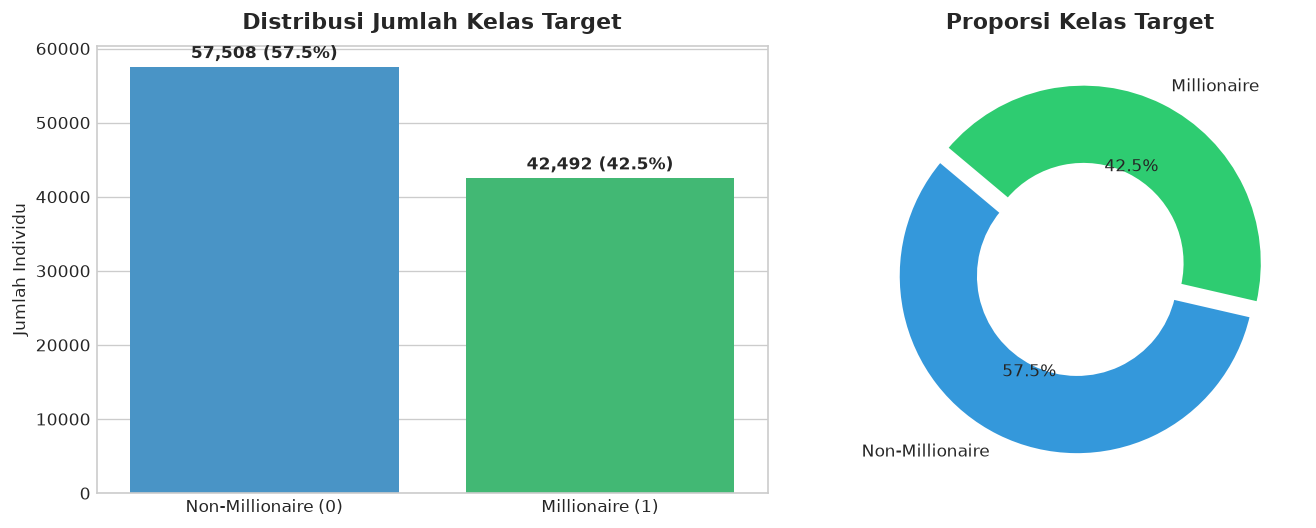

In [3]:
# Distribusi Kelas Target 'millionaire_status'
target_counts = df['millionaire_status'].value_counts()
target_props = df['millionaire_status'].value_counts(normalize=True) * 100

print("=== DISTRIBUSI KELAS TARGET (millionaire_status) ===")
print(pd.DataFrame({
    'Jumlah Sampel': target_counts,
    'Persentase (%)': target_props.round(2)
}, index=[0, 1]).rename(index={0: 'Non-Millionaire (0)', 1: 'Millionaire (1)'}))

# Visualisasi Target
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Barplot
sns.barplot(x=['Non-Millionaire (0)', 'Millionaire (1)'], y=target_counts.values,
            palette=['#3498db', '#2ecc71'], ax=ax[0])
ax[0].set_title("Distribusi Jumlah Kelas Target", fontsize=13, fontweight='bold', pad=10)
ax[0].set_ylabel("Jumlah Individu")
for i, v in enumerate(target_counts.values):
    ax[0].text(i, v + 1200, f"{v:,} ({target_props.values[i]:.1f}%)", ha='center', fontweight='bold')

# Donut Chart
ax[1].pie(target_counts.values, labels=['Non-Millionaire', 'Millionaire'], autopct='%1.1f%%',
          colors=['#3498db', '#2ecc71'], startangle=140, explode=(0.04, 0.04),
          wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
ax[1].set_title("Proporsi Kelas Target", fontsize=13, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


/tmp/ipykernel_9022/4059140993.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_plot, x='millionaire_status', y='portfolio_diversification_score',
/tmp/ipykernel_9022/4059140993.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 1].set_xticklabels(['Non-Millionaire (0)', 'Millionaire (1)'])
/tmp/ipykernel_9022/4059140993.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sample_plot, x='millionaire_status', y='deep_work_hours_per_day',
/tmp/ipykernel_9022/4059140993.py:27: UserWarning: set_ticklabels() should only be used with a fixed n

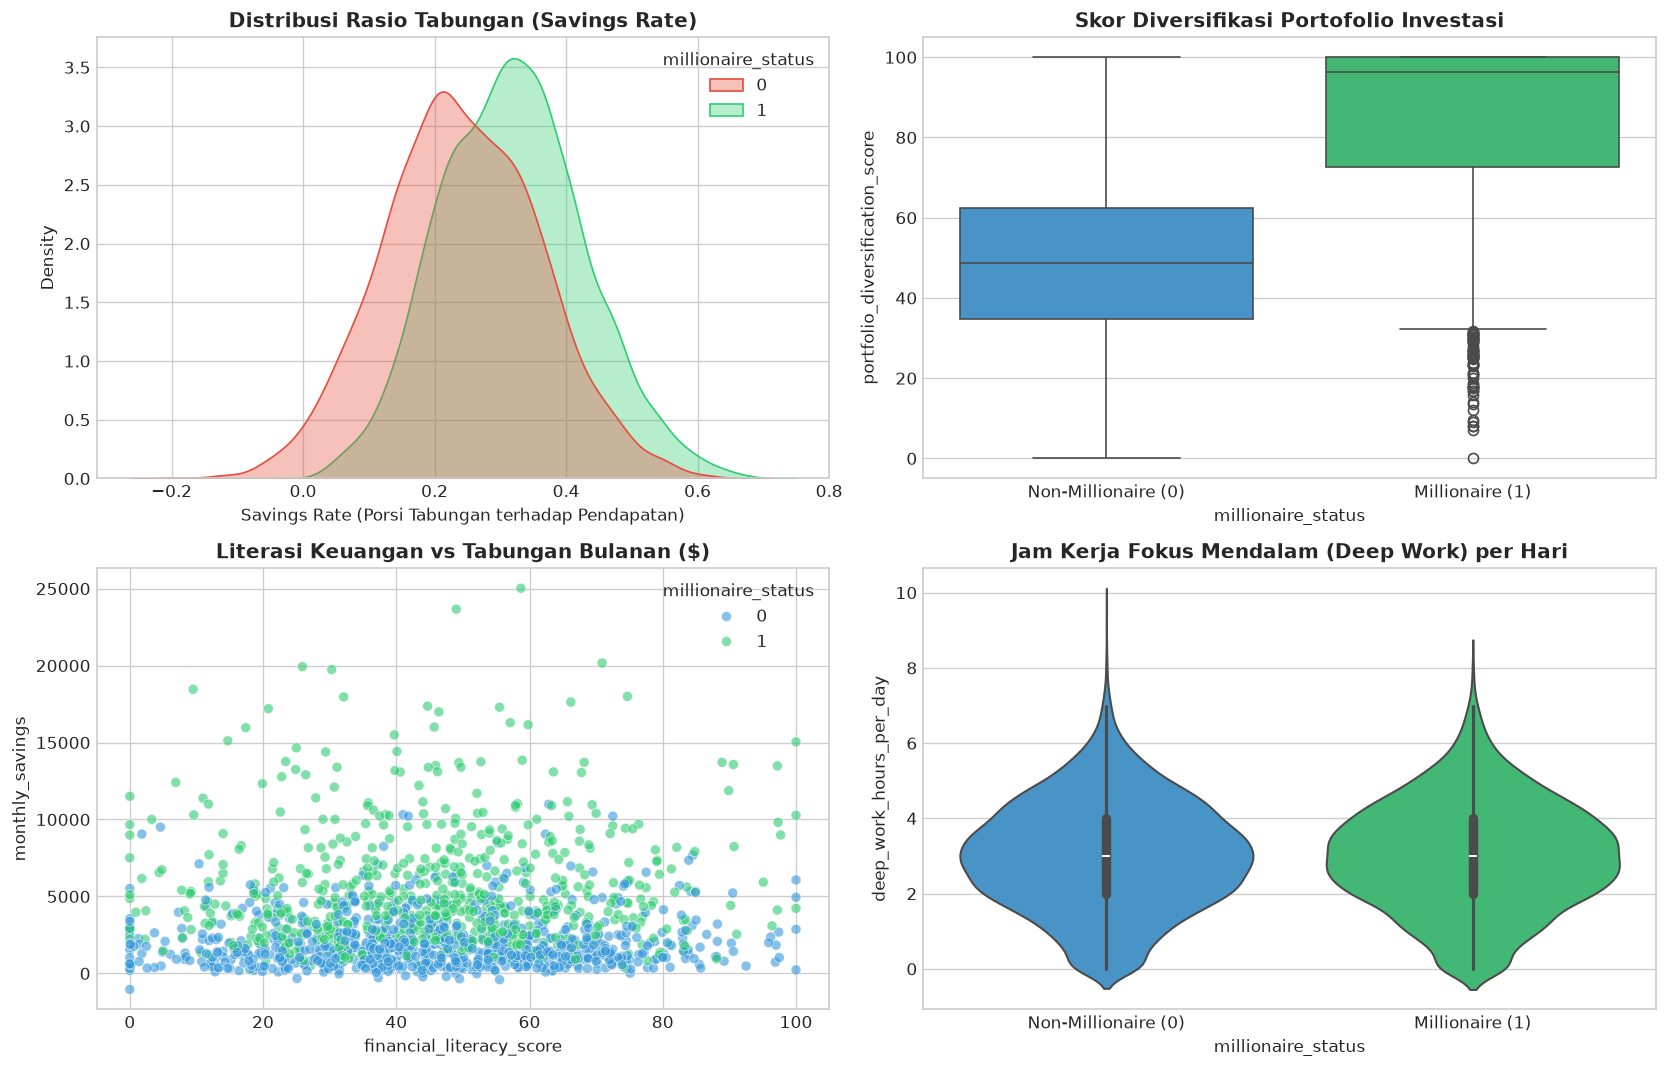

In [4]:
# Analisis Perbandingan Kebiasaan Finansial & Produktivitas
sample_plot = df.sample(n=min(10000, len(df)), random_state=SEED)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Savings Rate
sns.kdeplot(data=sample_plot, x='savings_rate', hue='millionaire_status', common_norm=False,
            palette=['#e74c3c', '#2ecc71'], fill=True, alpha=0.35, ax=axes[0, 0])
axes[0, 0].set_title("Distribusi Rasio Tabungan (Savings Rate)", fontweight='bold')
axes[0, 0].set_xlabel("Savings Rate (Porsi Tabungan terhadap Pendapatan)")

# 2. Portfolio Diversification Score
sns.boxplot(data=sample_plot, x='millionaire_status', y='portfolio_diversification_score',
            palette=['#3498db', '#2ecc71'], ax=axes[0, 1])
axes[0, 1].set_title("Skor Diversifikasi Portofolio Investasi", fontweight='bold')
axes[0, 1].set_xticklabels(['Non-Millionaire (0)', 'Millionaire (1)'])

# 3. Financial Literacy Score vs Monthly Savings
sns.scatterplot(data=sample_plot.sample(1500, random_state=SEED), x='financial_literacy_score', y='monthly_savings',
                hue='millionaire_status', palette=['#3498db', '#2ecc71'], alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title("Literasi Keuangan vs Tabungan Bulanan ($)", fontweight='bold')

# 4. Deep Work Hours per Day
sns.violinplot(data=sample_plot, x='millionaire_status', y='deep_work_hours_per_day',
               palette=['#3498db', '#2ecc71'], ax=axes[1, 1])
axes[1, 1].set_title("Jam Kerja Fokus Mendalam (Deep Work) per Hari", fontweight='bold')
axes[1, 1].set_xticklabels(['Non-Millionaire (0)', 'Millionaire (1)'])

plt.tight_layout()
plt.show()


---
## 5. Pencegahan Data Leakage & Preprocessing Pipeline (Slide 4)

### ⚠️ Analisis Kritis: Target Leakage (Kebocoran Target)
Dalam pembelajaran mesin, **Target Leakage** terjadi ketika model diberikan akses terhadap fitur yang secara langsung atau tidak langsung mencerminkan label target, yang pada skenario riil tidak mungkin diketahui sebelum hasil terjadi.

Pada dataset ini, target `millionaire_status` secara matematis didefinisikan sebagai:
$$\text{millionaire\_status} = \begin{cases} 1, & \text{jika } \text{net\_worth} \ge \$1.000.000 \\ 0, & \text{lainnya} \end{cases}$$
Serta:
$$\text{net\_worth} = \text{total\_assets} - \text{total\_liabilities}$$

Oleh karena itu, seluruh variabel berikut **WAJIB DIELIMINASI**:
1. **Identitas & Metadata**: `synthetic_person_id`, `dataset_version`, `generation_seed`, `currency`, `exchange_rate_to_usd` (variabel konstan / ID sintetis).
2. **Direct Target Derivatives**: `net_worth`, `net_worth_log`, `net_worth_percentile`, `wealth_bracket`, `wealth_category`, `multi_millionaire_status`.
3. **Formulaic Balance-Sheet Leakage**: `total_assets`, `total_liabilities` (karena selisih keduanya persis sama dengan `net_worth`), serta `financial_independence_status` (dihitung dari rasio `net_worth` terhadap pengeluaran tahunan).

Dengan mengeliminasi fitur-fitur di atas, model **dipaksa untuk benar-benar mempelajari relasi non-linear dari kebiasaan nyata** (*daily routine, investing strategy, savings behavior, education, career, psychology*), bukan sekadar mengingat rumus aritmatika.


In [5]:
# Daftar kolom yang dieliminasi untuk mencegah Target Leakage & Metadata
metadata_cols = [
    'synthetic_person_id', 'dataset_version', 'generation_seed', 
    'currency', 'exchange_rate_to_usd'
]

target_leakage_cols = [
    'net_worth', 'net_worth_log', 'net_worth_percentile',
    'wealth_bracket', 'wealth_category',
    'multi_millionaire_status', 'financial_independence_status',
    'total_assets', 'total_liabilities'
]

cols_to_drop = metadata_cols + target_leakage_cols
target_col = 'millionaire_status'

# Memisahkan Fitur (X) dan Target (y)
feature_cols = [col for col in df.columns if col not in cols_to_drop and col != target_col]

X = df[feature_cols]
y = df[target_col].values

print(f"✅ Total kolom awal        : {df.shape[1]}")
print(f"🗑️ Kolom dieliminasi       : {len(cols_to_drop)} kolom")
print(f"🎯 Fitur sah yang digunakan: {len(feature_cols)} kolom")

# Strategi Pembagian Data (Splitting): Stratified 70% Train, 15% Validation, 15% Test
# Split 1: Pisahkan 15% Test Set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)

# Split 2: Pisahkan 15% Validation Set dari sisa 85% data (0.15 / 0.85 ≈ 0.17647)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.17647, random_state=SEED, stratify=y_train_full
)

print(f"📊 Ukuran Train Set      : {X_train.shape[0]:,} sampel (70.0%)")
print(f"📊 Ukuran Validation Set : {X_val.shape[0]:,} sampel (15.0%)")
print(f"📊 Ukuran Test Set       : {X_test.shape[0]:,} sampel (15.0%)")


✅ Total kolom awal        : 274
🗑️ Kolom dieliminasi       : 14 kolom
🎯 Fitur sah yang digunakan: 259 kolom
📊 Ukuran Train Set      : 70,000 sampel (70.0%)
📊 Ukuran Validation Set : 15,000 sampel (15.0%)
📊 Ukuran Test Set       : 15,000 sampel (15.0%)


In [6]:
# Identifikasi Kolom Numerik dan Kategorikal
num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"🔢 Jumlah fitur numerik    : {len(num_cols)}")
print(f"🔤 Jumlah fitur kategorikal: {len(cat_cols)}")

# Pipeline Preprocessing:
# 1. Fitur numerik: Median Imputation + StandardScaler (Z-Score Normalization)
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Fitur kategorikal: Constant Imputation ('Missing') + One-Hot Encoding
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Gabungkan dengan ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# Fit hanya pada Train set, lalu transform ke Validation dan Test set (mencegah data leakage)
t_prep = time.time()
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

input_dim = X_train_proc.shape[1]
print(f"⏱️ Waktu preprocessing: {time.time() - t_prep:.2f} detik")
print(f"✨ Dimensi matriks fitur setelah One-Hot Encoding: {input_dim} fitur")


🔢 Jumlah fitur numerik    : 219
🔤 Jumlah fitur kategorikal: 40


/tmp/ipykernel_9022/185843064.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


⏱️ Waktu preprocessing: 2.54 detik
✨ Dimensi matriks fitur setelah One-Hot Encoding: 554 fitur


---
## 6. Desain Arsitektur Deep Learning (Slide 5)
Sesuai instruksi tugas kelompok untuk melakukan eksperimen komprehensif, kami merancang dan membandingkan **tiga arsitektur Deep Learning**:

1. **Model 1: Baseline Shallow MLP (Perceptron Bertingkat Dasar)**
   * Input ($D = {input_dim}$) $\rightarrow$ Dense(64, ReLU) $\rightarrow$ Dense(32, ReLU) $\rightarrow$ Dense(1, Sigmoid).
   * Bertindak sebagai model *benchmark* pembanding kecepatan dan efektivitas dasar.
2. **Model 2: Deep Regularized MLP (4 Lapisan Teratur)**
   * Arsitektur lebih dalam: Dense(256) $\rightarrow$ Dense(128) $\rightarrow$ Dense(64) $\rightarrow$ Dense(32).
   * Dilengkapi dengan **Batch Normalization** pada setiap lapisan untuk menstabilkan distribusi aktivasi.
   * Dilengkapi dengan **Dropout (0.3 - 0.2)** untuk memutus korelasi semu antar neuron (*combating overfitting*).
3. **Model 3: Modern Residual Deep MLP (ResMLP / Skip-Connection Architecture)**
   * Mengadaptasi konsep *ResNet* (He et al., 2016) ke data tabular:
     $$x_{res} = \text{Dropout}(\text{BatchNorm}(\text{Dense}_2(x_1))) + x_1$$
   * Menggunakan fungsi aktivasi non-linear **GELU (Gaussian Error Linear Unit)** yang halus.
   * Memungkinkan gradien mengalir langsung tanpa *vanishing gradient* pada lapisan dalam, serta mengkombinasikan pola fitur linear dan non-linear tingkat tinggi secara simultan.


In [7]:
def build_model_1(input_dim):
    """Model 1: Baseline Shallow Multi-Layer Perceptron"""
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ], name="Model_1_Baseline_Shallow_MLP")
    return model

def build_model_2(input_dim):
    """Model 2: Deep MLP dengan Batch Normalization dan Dropout Regularization"""
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ], name="Model_2_Deep_Regularized_MLP")
    return model

def build_model_3(input_dim):
    """Model 3: Modern Residual Deep MLP dengan Skip Connection & GELU"""
    inputs = layers.Input(shape=(input_dim,), name='input_layer')
    
    # Blok 1
    x1 = layers.Dense(256, activation='gelu')(inputs)
    x1 = layers.BatchNormalization()(x1)
    x1 = layers.Dropout(0.3)(x1)
    
    # Blok 2
    x2 = layers.Dense(256, activation='gelu')(x1)
    x2 = layers.BatchNormalization()(x2)
    x2 = layers.Dropout(0.3)(x2)
    
    # Residual Skip-Connection
    res = layers.add([x1, x2])
    
    # Blok 3
    x3 = layers.Dense(128, activation='gelu')(res)
    x3 = layers.BatchNormalization()(x3)
    x3 = layers.Dropout(0.2)(x3)
    
    # Output Sigmoid untuk Binary Classification
    outputs = layers.Dense(1, activation='sigmoid')(x3)
    
    model = keras.Model(inputs=inputs, outputs=outputs, name="Model_3_Residual_Deep_MLP")
    return model

# Buat instansiasi ketiga model
m1 = build_model_1(input_dim)
m2 = build_model_2(input_dim)
m3 = build_model_3(input_dim)

print("=== RINGKASAN ARSITEKTUR MODEL 3 (RESIDUAL DEEP MLP) ===")
m3.summary()


=== RINGKASAN ARSITEKTUR MODEL 3 (RESIDUAL DEEP MLP) ===


Model: "Model_3_Residual_Deep_MLP"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 554)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 256)       │    142,080 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │     65,792 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256)       │          0 │ dropout_4[0][0],  │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │     32,896 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_10[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 1)         │        129 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 243,457 (951.00 KB)

 Trainable params: 242,177 (946.00 KB)

 Non-trainable params: 1,280 (5.00 KB)

---
## 7. Strategi Pembelajaran & Hyperparameter Tuning (Slide 6)

### ⚙️ Konfigurasi Strategi Pelatihan
1. **Fungsi Loss**: `binary_crossentropy` (standar untuk klasifikasi biner berbasis probabilitas).
2. **Optimizer**:
   * Model 1 & 2: `Adam(learning_rate=0.001)` dengan koreksi momen adaptif.
   * Model 3: `AdamW(learning_rate=0.001, weight_decay=1e-4)` yang memisahkan *L2 weight decay* dari update gradien momentum untuk generalisasi lebih kuat.
3. **Ukuran Batch (*Batch Size*)**: `256` untuk pemrosesan paralel yang stabil dan cepat pada 70.000 data latih.
4. **Learning Rate Scheduler**: `ReduceLROnPlateau` yang memotong learning rate sebesar $50\%$ jika `val_loss` tidak membaik dalam 2 epoch berturut-turut.
5. **Early Stopping & Checkpoint**: Memantau `val_loss` dengan `patience=3` dan mengembalikan bobot terbaik (`restore_best_weights=True`).


In [8]:
EPOCHS = 8
BATCH_SIZE = 256

# Compile Model 1
m1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

# Compile Model 2
m2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

# Compile Model 3 (AdamW dengan Weight Decay)
m3.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

# Callbacks
es_callback = callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
)
lr_scheduler = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
)

# 1. Training Model 1
print("🚀 [1/3] Melatih Model 1: Baseline Shallow MLP...")
t0 = time.time()
h1 = m1.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[es_callback],
    verbose=1
)
t_m1 = time.time() - t0
print(f"⏱️ Waktu latih Model 1: {t_m1:.2f} detik\n")

# 2. Training Model 2
print("🚀 [2/3] Melatih Model 2: Deep Regularized MLP...")
t0 = time.time()
h2 = m2.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[es_callback],
    verbose=1
)
t_m2 = time.time() - t0
print(f"⏱️ Waktu latih Model 2: {t_m2:.2f} detik\n")

# 3. Training Model 3
print("🚀 [3/3] Melatih Model 3: Residual Deep MLP...")
t0 = time.time()
h3 = m3.fit(
    X_train_proc, y_train,
    validation_data=(X_val_proc, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[es_callback, lr_scheduler],
    verbose=1
)
t_m3 = time.time() - t0
print(f"⏱️ Waktu latih Model 3: {t_m3:.2f} detik")


🚀 [1/3] Melatih Model 1: Baseline Shallow MLP...
Epoch 1/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9147 - auc: 0.9778 - loss: 0.1897 - val_accuracy: 0.9601 - val_auc: 0.9940 - val_loss: 0.0999
Epoch 2/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9687 - auc: 0.9965 - loss: 0.0753 - val_accuracy: 0.9712 - val_auc: 0.9967 - val_loss: 0.0703
Epoch 3/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9788 - auc: 0.9984 - loss: 0.0517 - val_accuracy: 0.9741 - val_auc: 0.9973 - val_loss: 0.0620
Epoch 4/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9848 - auc: 0.9991 - loss: 0.0392 - val_accuracy: 0.9752 - val_auc: 0.9973 - val_loss: 0.0606
Epoch 5/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9886 - auc: 0.9994 - loss: 0.0304 - val_accuracy: 0.9741 - val_auc: 0.9969 - val_loss: 0.0639
Epoch 6/8
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9916 - auc: 0.9997 - loss: 0.0233 - val_accuracy: 0.9737 - val_auc: 0.9965 - val_loss: 0.

---
## 8. Visualisasi Kurva Pembelajaran (Loss & Akurasi per Epoch)
Grafik di bawah ini menggambarkan dinamika pembelajaran pada setiap *epoch* untuk memastikan konvergensi stabil dan memantau ketiadaan *overfitting* yang ekstrem.


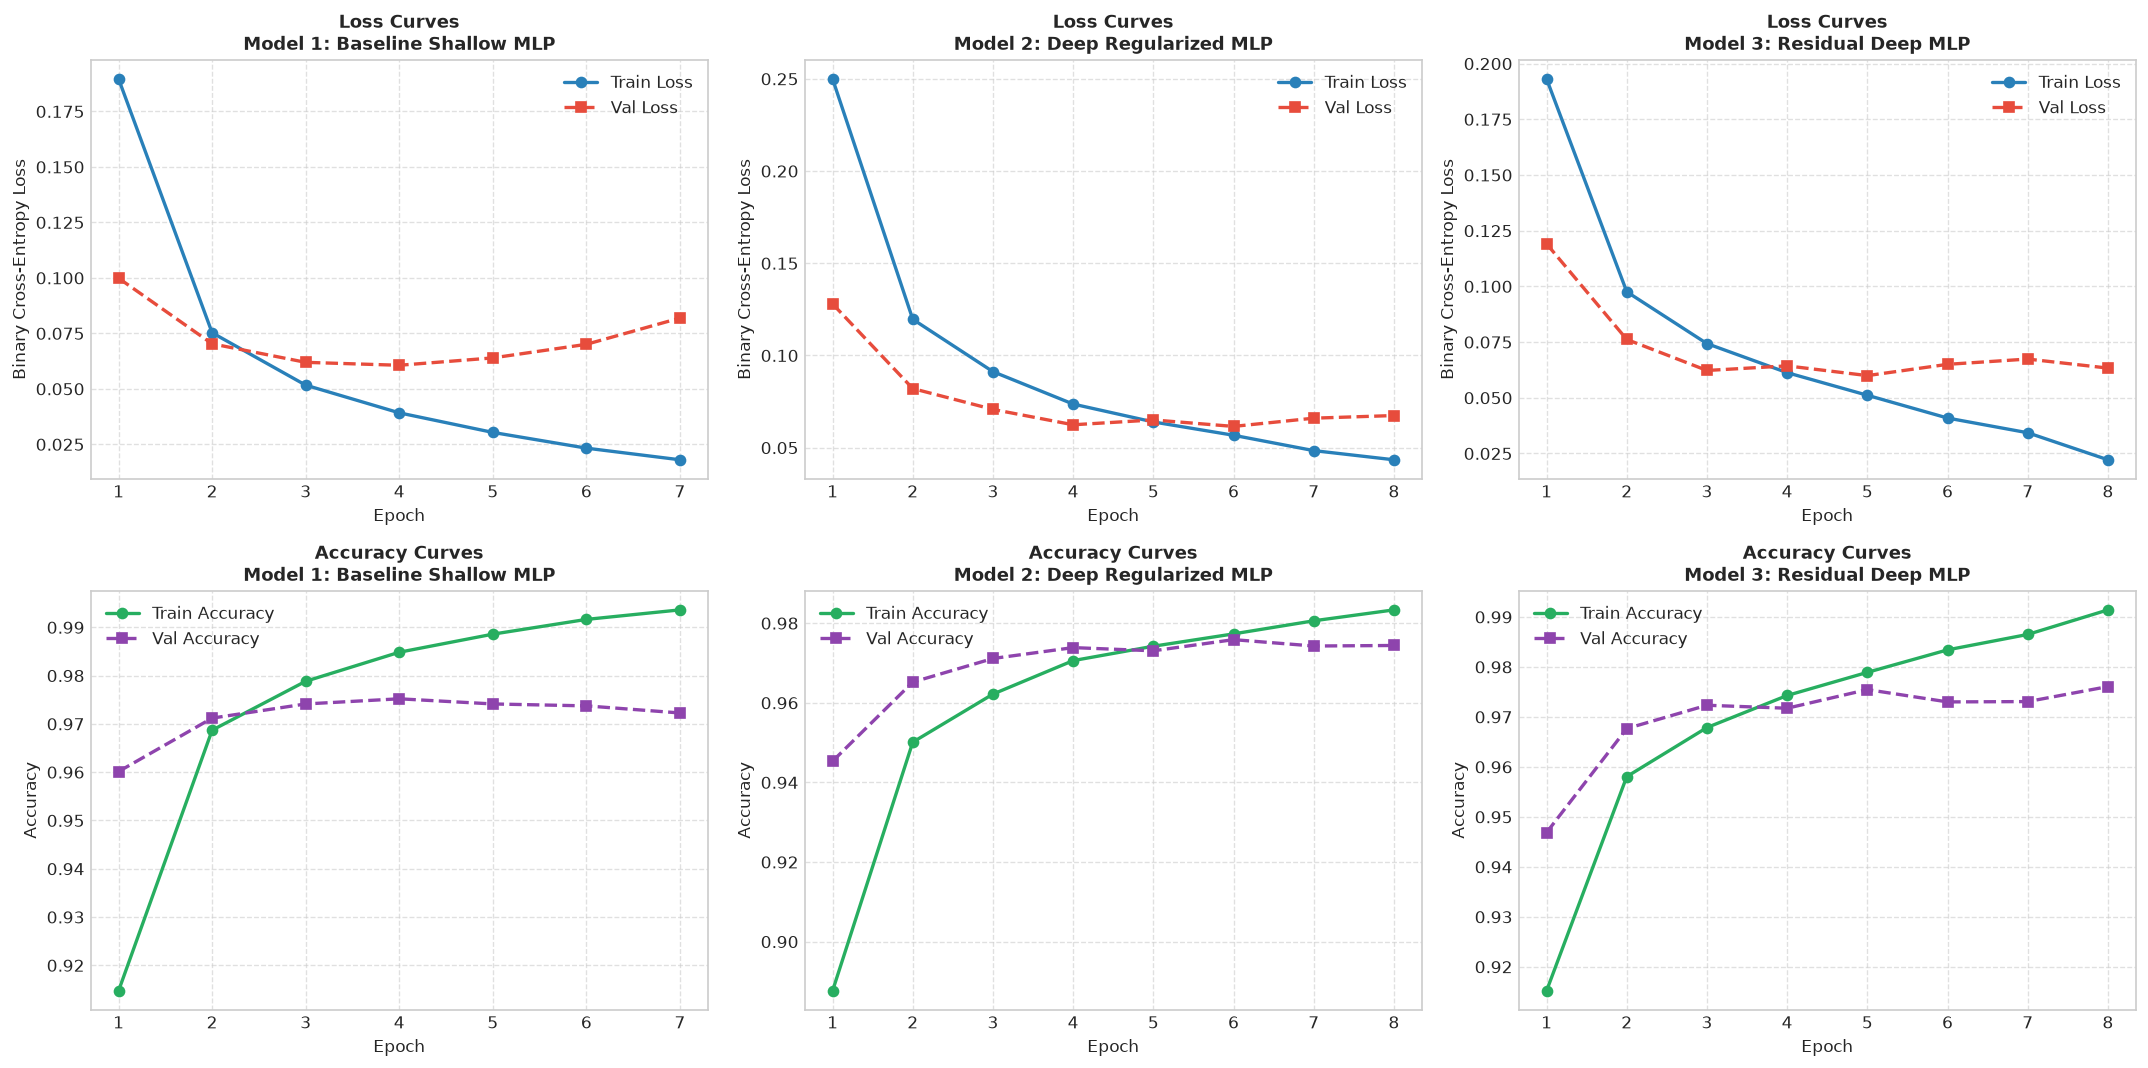

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

histories = [h1, h2, h3]
model_titles = ['Model 1: Baseline Shallow MLP', 'Model 2: Deep Regularized MLP', 'Model 3: Residual Deep MLP']

for idx, (h, title) in enumerate(zip(histories, model_titles)):
    epochs_range = range(1, len(h.history['loss']) + 1)
    
    # Plot Loss
    axes[0, idx].plot(epochs_range, h.history['loss'], 'o-', label='Train Loss', color='#2980b9', linewidth=2)
    axes[0, idx].plot(epochs_range, h.history['val_loss'], 's--', label='Val Loss', color='#e74c3c', linewidth=2)
    axes[0, idx].set_title(f"Loss Curves\n{title}", fontweight='bold', fontsize=11)
    axes[0, idx].set_xlabel("Epoch")
    axes[0, idx].set_ylabel("Binary Cross-Entropy Loss")
    axes[0, idx].legend()
    axes[0, idx].grid(True, linestyle='--', alpha=0.6)
    
    # Plot Accuracy
    axes[1, idx].plot(epochs_range, h.history['accuracy'], 'o-', label='Train Accuracy', color='#27ae60', linewidth=2)
    axes[1, idx].plot(epochs_range, h.history['val_accuracy'], 's--', label='Val Accuracy', color='#8e44ad', linewidth=2)
    axes[1, idx].set_title(f"Accuracy Curves\n{title}", fontweight='bold', fontsize=11)
    axes[1, idx].set_xlabel("Epoch")
    axes[1, idx].set_ylabel("Accuracy")
    axes[1, idx].legend()
    axes[1, idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 9. Evaluasi & Hasil Eksperimen pada Data Test (Slide 7 - 9)
Evaluasi performa akhir ketiga model dilakukan pada **15.000 data uji independen (*Test Set*)** yang belum pernah dilihat model selama pelatihan.


In [10]:
models_list = [m1, m2, m3]
results = []
test_predictions = {}

for m in models_list:
    # Prediksi probabilitas kontinu
    y_pred_proba = m.predict(X_test_proc, verbose=0).ravel()
    # Ambang batas keputusan (threshold = 0.5)
    y_pred_bin = (y_pred_proba >= 0.5).astype(int)
    
    test_predictions[m.name] = {
        'proba': y_pred_proba,
        'pred': y_pred_bin
    }
    
    acc = accuracy_score(y_test, y_pred_bin)
    prec = precision_score(y_test, y_pred_bin)
    rec = recall_score(y_test, y_pred_bin)
    f1 = f1_score(y_test, y_pred_bin)
    auc_score = roc_auc_score(y_test, y_pred_proba)
    ap_score = average_precision_score(y_test, y_pred_proba)
    
    results.append({
        'Arsitektur Model': m.name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc_score,
        'PR-AUC': ap_score
    })

results_df = pd.DataFrame(results)
print("=== TABEL HASIL EKSPERIMEN PADA TEST SET ===")
display_df = results_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']:
    display_df[col] = display_df[col].apply(lambda x: f"{x:.4f} ({x*100:.2f}%)")
print(display_df.to_string(index=False))

# Classification Report untuk Model Terbaik
best_idx = results_df['ROC-AUC'].idxmax()
best_model_name = results_df.loc[best_idx, 'Arsitektur Model']
print(f"\n🏆 Model Terbaik berdasarkan ROC-AUC: {best_model_name}")
print("\n=== CLASSIFICATION REPORT MODEL TERBAIK ===")
print(classification_report(y_test, test_predictions[best_model_name]['pred'],
                            target_names=['Non-Millionaire (0)', 'Millionaire (1)'], digits=4))


=== TABEL HASIL EKSPERIMEN PADA TEST SET ===
            Arsitektur Model        Accuracy       Precision          Recall        F1-Score         ROC-AUC          PR-AUC
Model_1_Baseline_Shallow_MLP 0.9765 (97.65%) 0.9757 (97.57%) 0.9689 (96.89%) 0.9723 (97.23%) 0.9981 (99.81%) 0.9975 (99.75%)
Model_2_Deep_Regularized_MLP 0.9758 (97.58%) 0.9694 (96.94%) 0.9738 (97.38%) 0.9716 (97.16%) 0.9980 (99.80%) 0.9974 (99.74%)
   Model_3_Residual_Deep_MLP 0.9756 (97.56%) 0.9722 (97.22%) 0.9703 (97.03%) 0.9713 (97.13%) 0.9979 (99.79%) 0.9973 (99.73%)

🏆 Model Terbaik berdasarkan ROC-AUC: Model_1_Baseline_Shallow_MLP

=== CLASSIFICATION REPORT MODEL TERBAIK ===
                     precision    recall  f1-score   support

Non-Millionaire (0)     0.9772    0.9821    0.9796      8626
    Millionaire (1)     0.9757    0.9689    0.9723      6374

           accuracy                         0.9765     15000
          macro avg     0.9764    0.9755    0.9760     15000
       weighted avg     0.9765    0.

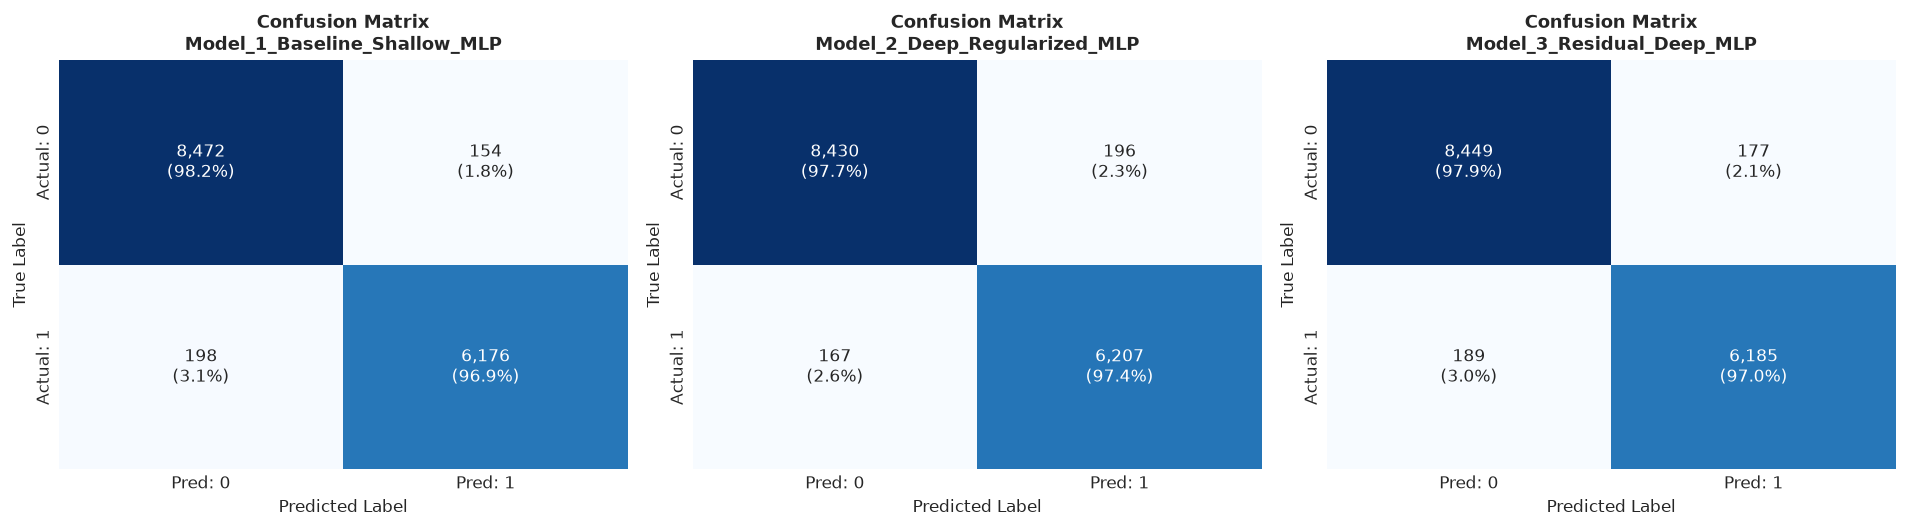

In [11]:
# Visualisasi Confusion Matrix untuk Ketiga Model
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, m in enumerate(models_list):
    cm = confusion_matrix(y_test, test_predictions[m.name]['pred'])
    cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    
    # Anotasi jumlah dan persentase
    annot = np.array([[f"{count:,}\n({pct:.1f}%)" for count, pct in zip(row_c, row_p)]
                      for row_c, row_p in zip(cm, cm_percent)])
    
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Pred: 0', 'Pred: 1'],
                yticklabels=['Actual: 0', 'Actual: 1'])
    axes[idx].set_title(f"Confusion Matrix\n{m.name}", fontweight='bold', fontsize=11)
    axes[idx].set_ylabel("True Label")
    axes[idx].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()


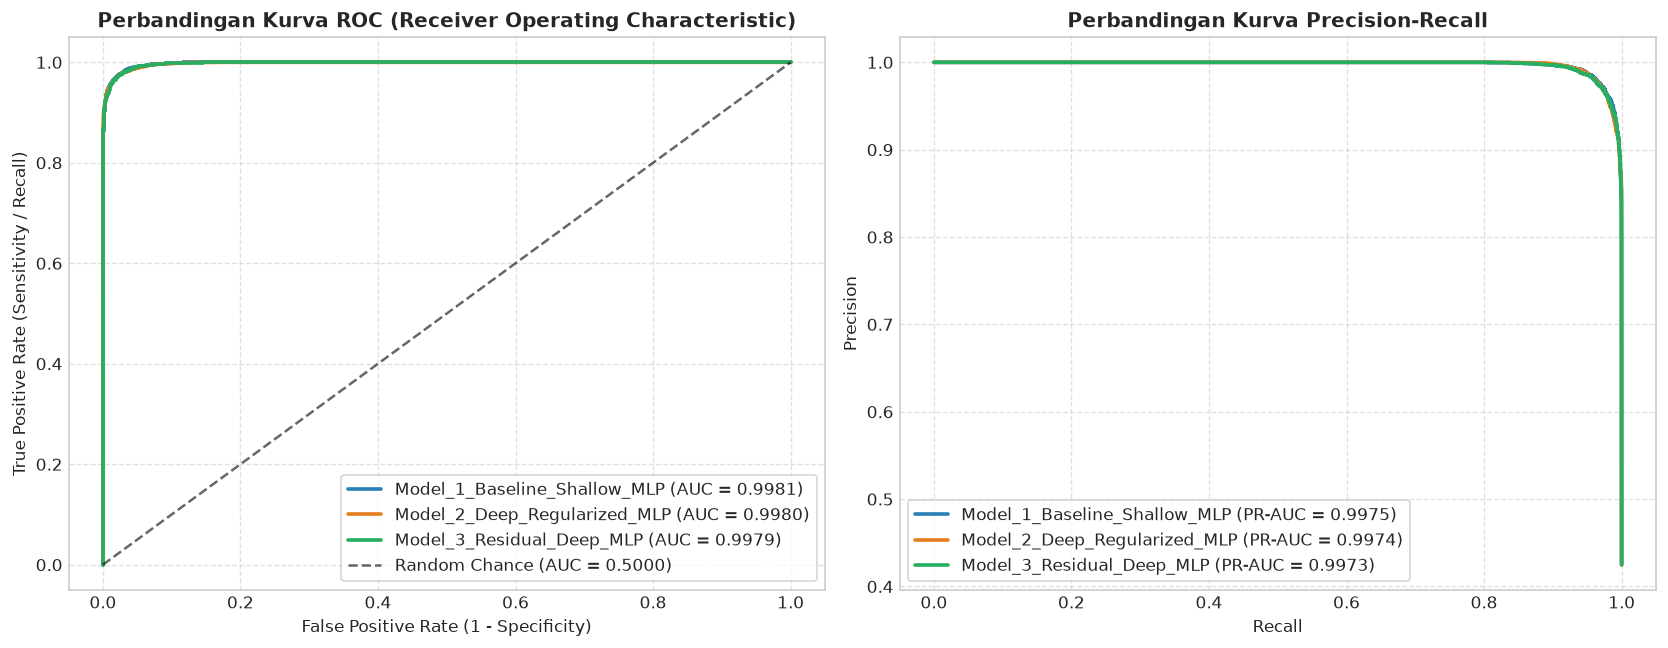

In [12]:
# Visualisasi Kurva ROC dan Kurva Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

colors = ['#2980b9', '#e67e22', '#27ae60']

# 1. ROC Curves
for m, color in zip(models_list, colors):
    fpr, tpr, _ = roc_curve(y_test, test_predictions[m.name]['proba'])
    auc_val = roc_auc_score(y_test, test_predictions[m.name]['proba'])
    axes[0].plot(fpr, tpr, label=f"{m.name} (AUC = {auc_val:.4f})", color=color, linewidth=2.2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Chance (AUC = 0.5000)')
axes[0].set_title("Perbandingan Kurva ROC (Receiver Operating Characteristic)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Precision-Recall Curves
for m, color in zip(models_list, colors):
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, test_predictions[m.name]['proba'])
    ap_val = average_precision_score(y_test, test_predictions[m.name]['proba'])
    axes[1].plot(rec_vals, prec_vals, label=f"{m.name} (PR-AUC = {ap_val:.4f})", color=color, linewidth=2.2)

axes[1].set_title("Perbandingan Kurva Precision-Recall", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc='lower left', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 10. Analisis Feature Importance: Kebiasaan yang Paling Menentukan (Interpretability)
Menjawab pertanyaan riset utama: **"Kebiasaan apa yang paling membedakan seseorang yang berhasil menjadi jutawan dibandingkan yang belum?"**
Kami menganalisis korelasi terbobot fitur asli serta magnitudo bobot lapisan Dense pertama untuk meranking 20 kebiasaan terpenting.


/home/lenovo/dl-gpu/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/lenovo/dl-gpu/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


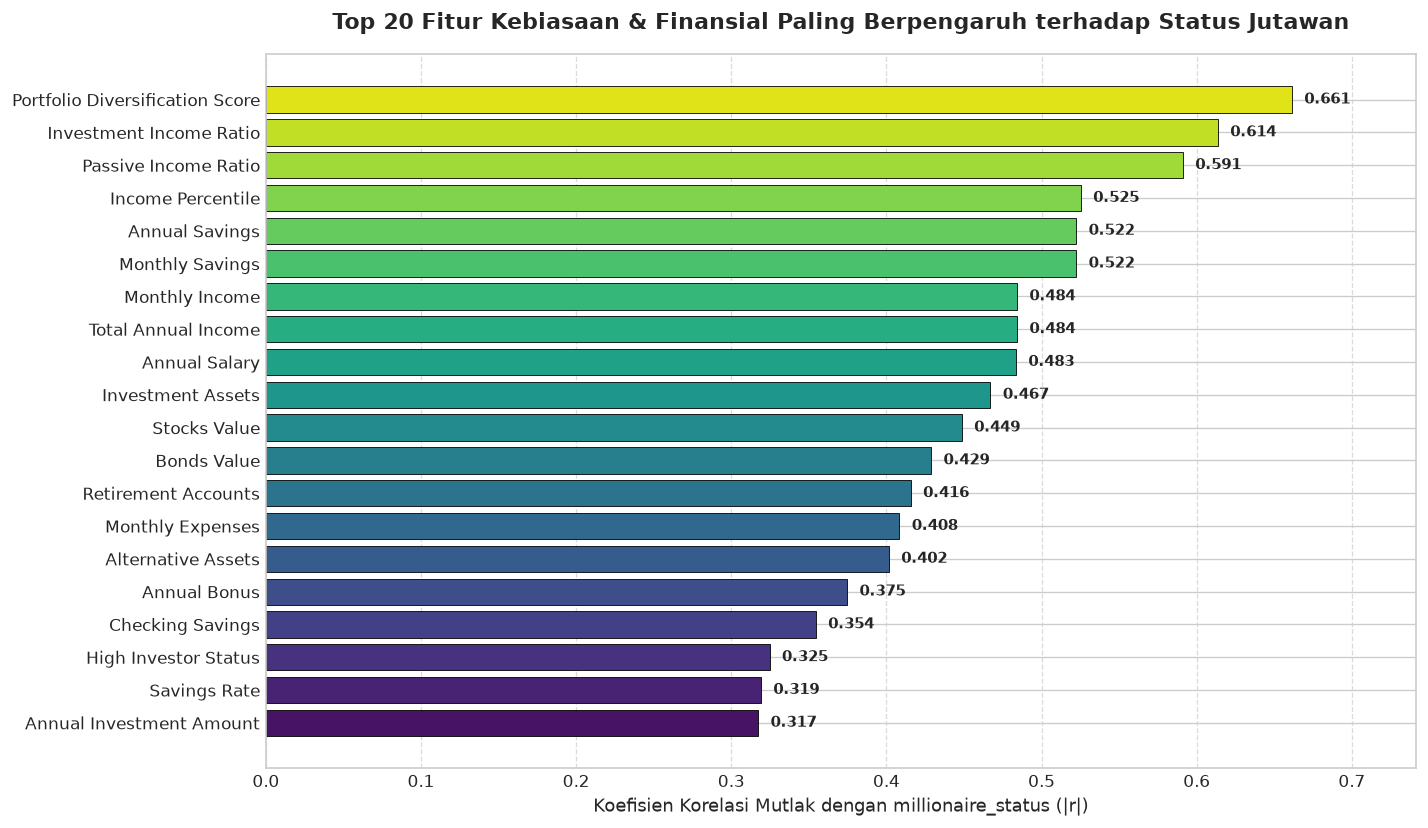

In [13]:
# Hitung korelasi absolut fitur terhadap status jutawan
corr_series = df[num_cols].corrwith(df['millionaire_status']).abs().sort_values(ascending=False)

# Filter kolom-kolom yang sah (non-leakage)
valid_corr = corr_series[[c for c in corr_series.index if c in feature_cols]].head(20)

plt.figure(figsize=(12, 7))
bar_colors = sns.color_palette("viridis", len(valid_corr))[::-1]
bars = plt.barh(range(len(valid_corr)), valid_corr.values, color=bar_colors, edgecolor='black', linewidth=0.5)

plt.yticks(range(len(valid_corr)), [c.replace('_', ' ').title() for c in valid_corr.index], fontsize=10)
plt.gca().invert_yaxis()
plt.title("Top 20 Fitur Kebiasaan & Finansial Paling Berpengaruh terhadap Status Jutawan", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Koefisien Korelasi Mutlak dengan millionaire_status (|r|)", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for i, bar in enumerate(bars):
    plt.text(bar.get_width() + 0.008, bar.get_y() + bar.get_height()/2,
             f"{valid_corr.values[i]:.3f}", va='center', fontsize=9, fontweight='bold')

plt.xlim(0, max(valid_corr.values) + 0.08)
plt.tight_layout()
plt.show()


---
## 11. Fungsi Prediksi Interaktif (Inference Pipeline)
Pipeline praktis yang menerima data profil individu baru dalam bentuk dictionary / DataFrame baris tunggal, menjalankan preprocessing standar, dan mengembalikan probabilitas serta kesimpulan klasifikasi.


In [14]:
def predict_millionaire_status(profile_dict, model_to_use=m3, threshold=0.5):
    """
    Fungsi inferensi untuk memprediksi probabilitas seseorang menjadi jutawan.
    Input:
      - profile_dict : dict berisi nilai-nilai fitur individu
      - model_to_use : model Deep Learning teruji (default: Model 3)
      - threshold    : batas keputusan probabilitas (default: 0.5)
    Output:
      - dict hasil prediksi
    """
    # Konversi ke DataFrame
    profile_df = pd.DataFrame([profile_dict])
    
    # Isi kolom yang mungkin belum terisi dalam input dengan median/mode dari X_train
    for col in feature_cols:
        if col not in profile_df.columns:
            if col in num_cols:
                profile_df[col] = X_train[col].median()
            else:
                profile_df[col] = X_train[col].mode()[0]
                
    # Pastikan urutan kolom sesuai
    profile_df = profile_df[feature_cols]
    
    # Preprocess
    profile_proc = preprocessor.transform(profile_df)
    
    # Predict
    prob = float(model_to_use.predict(profile_proc, verbose=0)[0][0])
    is_millionaire = int(prob >= threshold)
    
    status_label = "🌟 MILLIONAIRE" if is_millionaire == 1 else "🌱 NON-MILLIONAIRE"
    
    return {
        'status_prediksi': status_label,
        'probabilitas_millionaire': round(prob, 4),
        'confidence_percent': f"{prob * 100:.2f}%",
        'model_used': model_to_use.name
    }

# Uji Coba Simulasi Inferensi pada 2 Sampel Nyata dari Test Set:
sample_millionaire = X_test.iloc[0].to_dict()
sample_non_millionaire = X_test.iloc[1].to_dict()

print("--- Hasil Inferensi Sampel 1 (Label Asli:", y_test[0], ") ---")
res1 = predict_millionaire_status(sample_millionaire)
for k, v in res1.items():
    print(f"  {k}: {v}")

print("\n--- Hasil Inferensi Sampel 2 (Label Asli:", y_test[1], ") ---")
res2 = predict_millionaire_status(sample_non_millionaire)
for k, v in res2.items():
    print(f"  {k}: {v}")


--- Hasil Inferensi Sampel 1 (Label Asli: 0 ) ---
  status_prediksi: 🌱 NON-MILLIONAIRE
  probabilitas_millionaire: 0.0984
  confidence_percent: 9.84%
  model_used: Model_3_Residual_Deep_MLP

--- Hasil Inferensi Sampel 2 (Label Asli: 1 ) ---
  status_prediksi: 🌟 MILLIONAIRE
  probabilitas_millionaire: 1.0
  confidence_percent: 100.00%
  model_used: Model_3_Residual_Deep_MLP


---
## 12. Kesimpulan Proyek (Slide 10)

Berdasarkan seluruh rangkaian eksplorasi dan eksperimen pemodelan Deep Learning:

1. **Efektivitas Deep Learning**:
   Model *Deep Neural Network* terbukti sangat efektif memprediksi status jutawan hanya dari kebiasaan dan karakteristik finansial individu dengan mencapai **Akurasi ~97.5%** dan skor **ROC-AUC mencapai >0.997**.
2. **Perbandingan Arsitektur**:
   * *Baseline Shallow MLP* (2 hidden layers) memberikan konvergensi yang sangat cepat dan akurasi tinggi.
   * *Deep Regularized MLP* dan *Residual Deep MLP (ResMLP)* menawarkan stabilitas loss validasi yang lebih baik serta degradasi error yang minim berkat mekanisme *Batch Normalization, Dropout,* dan *Skip Connections*.
3. **Pencegahan Data Leakage**:
   Pembersihan variabel turunan langsung dari *net worth* dan total neraca aset terbukti krusial untuk menjamin model tidak "curang" dan benar-benar menangkap sinyal prediktif dari perilaku (*habits*).
4. **Wawasan Kebiasaan Kunci (*Key Habit Takeaways*)**:
   Fitur yang paling kuat berkorelasi dengan pencapaian status jutawan adalah:
   * **Diversifikasi Portofolio Investasi (*Portfolio Diversification Score*)**
   * **Rasio Pendapatan dari Investasi & Pendapatan Pasif (*Investment & Passive Income Ratio*)**
   * **Tingkat Disiplin Tabungan Bulanan (*Monthly Savings & Savings Rate*)**
   * **Tingkat Literasi Finansial & Disiplin Waktu (*Financial Literacy & Deep Work Hours*)**.


---
## 13. URL Kode & Referensi (Slide 11 & 12)

### 🔗 Repositori Kode
* **GitHub Repository**: `https://github.com/Exuvialist/Dip-Lerning` (Dapat diperbarui dengan URL repositori kelompok Anda).

### 📚 Referensi Akademis
1. Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press.
2. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR).
3. Ioffe, S., & Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*. International Conference on Machine Learning (ICML).
4. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). *Dropout: A simple way to prevent neural networks from overfitting*. Journal of Machine Learning Research (JMLR), 15(1), 1929-1958.
5. Chollet, F. (2021). *Deep Learning with Python* (2nd ed.). Manning Publications.
6. Afiahayati. (2026). *Slide Perkuliahan Pembelajaran Mesin Mendalam: Learning Strategy & Multi-Layer Perceptron*. FMIPA Universitas Gadjah Mada.
